In [1]:
%matplotlib inline

import importlib
import sys
import numpy as np
import matplotlib.pyplot as plt
import detector_model_v4 as dm

dm = importlib.reload(dm)

**Среднее и дисперсия числа фотонов**

Теория: 10000.0
Среднее: 10000.6002
Дисперсия: 10024.238183778376


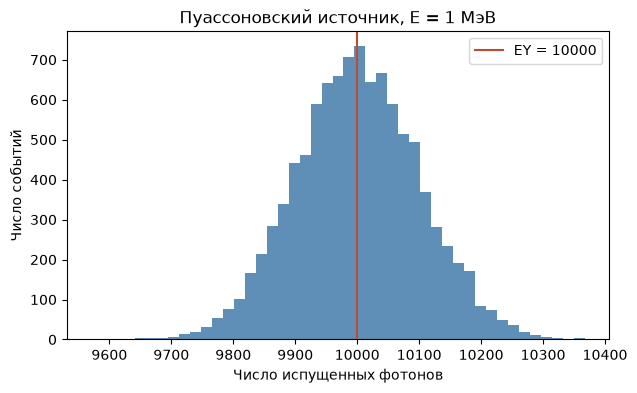

In [2]:
source = dm.Source(Y=10_000)
rng = np.random.default_rng(2026)
E = 1.0

counts = np.array([source.photon_count(E, rng) for _ in range(10_000)])
print("Теория:", E * source.Y)
print("Среднее:", counts.mean())
print("Дисперсия:", counts.var(ddof=1))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(counts, bins=45, color="#3773a5", alpha=0.8)
ax.axvline(E * source.Y, color="#bd4b32", label="EY = 10000")
ax.set(xlabel="Число испущенных фотонов", ylabel="Число событий",
       title="Пуассоновский источник, E = 1 МэВ")
ax.legend()
plt.show()

In [3]:
generator = source.emit_generator(0.025, np.random.default_rng(2026))
first = next(generator)
total = 1 + sum(1 for _ in generator)
print("Всего фотонов:", total)

Всего фотонов: 233


In [4]:
sizes = []
for batch in source.emit_batches(0.025, np.random.default_rng(2026), batch_size=100):
    print("Форма пакета:", batch.shape)
    sizes.append(len(batch))

print("Размеры пакетов:", sizes)
print("Всего фотонов:", sum(sizes))

Форма пакета: (100, 3)
Форма пакета: (100, 3)
Форма пакета: (33, 3)
Размеры пакетов: [100, 100, 33]
Всего фотонов: 233


In [5]:
E_check = 0.025
array = source.emit(E_check, np.random.default_rng(42))
single = np.array(list(source.emit_generator(E_check, np.random.default_rng(42))))
batches = list(source.emit_batches(E_check, np.random.default_rng(42), 100))
joined = np.concatenate(batches) if batches else np.empty((0, 3))

print(array.shape, single.shape, joined.shape)
print("Массив и отдельные фотоны:", np.allclose(array, single))
print("Массив и пакеты:", np.allclose(array, joined))
assert np.allclose(array, single)
assert np.allclose(array, joined)

(263, 3) (263, 3) (263, 3)
Массив и отдельные фотоны: True
Массив и пакеты: True
